In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint,ReduceLROnPlateau

In [2]:
# Masaüstündeki dosya yolu (kullanıcı adı kısmını düzenlemeyi unutmayın)
file_path = "household_power_consumption.txt"

# Veriyi yüklerken tarihleri birleştirme işlemini daha uygun bir yöntemle yapıyoruz
data = pd.read_csv(file_path, sep=';', na_values=['?'], low_memory=False)

# 'Date' ve 'Time' sütunlarını birleştirip 'timestamp' sütunu olarak ekliyoruz
data['timestamp'] = pd.to_datetime(data['Date'] + ' ' + data['Time'], format='%d/%m/%Y %H:%M:%S')

# İlk birkaç satırı kontrol edelim
print(data.head())

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  \
0              18.4             0.0             1.0            17.0   
1              23.0             0.0             1.0            16.0   
2              23.0             0.0             2.0            17.0   
3              23.0             0.0             1.0            17.0   
4              15.8             0.0             1.0            17.0   

            timestamp  
0 2006-12-16 17:24:00  
1 2006-12-16 17:25:00  
2 2006-12-16 17:26:0

In [18]:
data.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,timestamp
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


In [3]:
# Eksik verileri kontrol et
print(data.isnull().sum())


# Eksik verileri ileri doldurma (forward fill) yöntemiyle doldurma
data.fillna(method='ffill', inplace=True)



Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
timestamp                    0
dtype: int64


In [4]:
# Sütun bazında eksik veri sayısını kontrol eder
missing_data = data.isnull().sum()
print(missing_data)


Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
timestamp                0
dtype: int64


In [5]:
# Scaling the 'Global_active_power' data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data[['Global_active_power']].values)


In [6]:
# Function to create the dataset for time series forecasting
def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

In [7]:
# Using the last 24 hours (time_step=24) to predict the next hour
time_step = 24
X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

In [8]:
# Splitting the data into training and testing sets (80% train, 20% test)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]


In [9]:
from tensorflow.keras.layers import Input

# LSTM modelini Input katmanı kullanarak yeniden yapılandırma
model = Sequential()

# Input katmanı ile giriş boyutunu tanımlayın
model.add(Input(shape=(time_step, 1)))

# LSTM katmanları
model.add(LSTM(50, return_sequences=True))
model.add(LSTM(50))

# Çıkış katmanı
model.add(Dense(1))

In [10]:
# Compiling the model
model.compile(loss='mean_squared_error', optimizer='adam')


In [11]:
# Callbackler
callbacks= [EarlyStopping(monitor="val_loss",patience=50,verbose=1,mode="min"),

            ModelCheckpoint(filepath="mymodel.keras",monitor="val_loss",mode="min",save_best_only=True,save_weights_only=False,verbose=1)]


In [12]:



# Modeli eğit (early stopping ile)
history = model.fit(X_train, y_train, 
                    validation_data=(X_test, y_test), 
                    epochs=20, 
                    batch_size=128, 
                    verbose=1, 
                    callbacks=callbacks)



Epoch 1/20
12971/12971 [==============================] - ETA: 0s - loss: 6.3559e-04
Epoch 1: val_loss improved from inf to 0.00037, saving model to mymodel.keras
12971/12971 [==============================] - 414s 32ms/step - loss: 6.3559e-04 - val_loss: 3.7385e-04
Epoch 2/20
12969/12971 [============================>.] - ETA: 0s - loss: 5.8928e-04
Epoch 2: val_loss improved from 0.00037 to 0.00037, saving model to mymodel.keras
12971/12971 [==============================] - 438s 34ms/step - loss: 5.8927e-04 - val_loss: 3.7152e-04
Epoch 3/20
 4705/12971 [=========>....................] - ETA: 5:07 - loss: 5.8289e-04

KeyboardInterrupt: 

In [21]:
# Predictions
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

51881/51881 ━━━━━━━━━━━━━━━━━━━━ 144s 3ms/step
12971/12971 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step


In [22]:
# Inverse scaling for both predictions
train_predict = scaler.inverse_transform(train_predict)
test_predict = scaler.inverse_transform(test_predict)


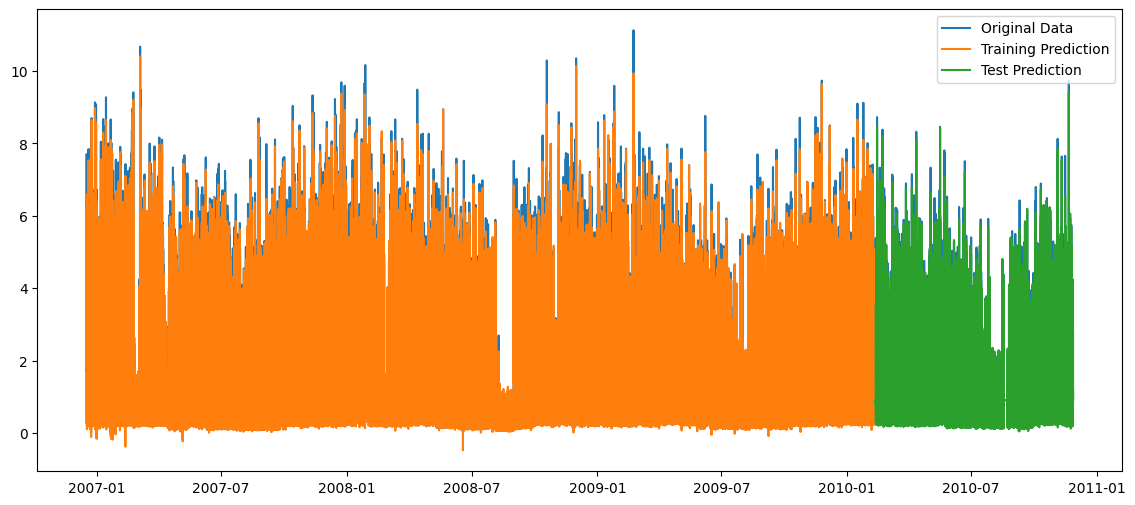

In [23]:
# Visualizing the original data along with training and testing predictions
plt.figure(figsize=(14,6))
plt.plot(data['timestamp'], scaler.inverse_transform(scaled_data), label='Original Data')
plt.plot(data['timestamp'][:len(train_predict)], train_predict, label='Training Prediction')
plt.plot(data['timestamp'][len(train_predict):(len(train_predict) + len(test_predict))], test_predict, label='Test Prediction')
plt.legend()
plt.show()